# Лабораторная работа 1R

# THEORY

## Introduction to R

## Invoke the R enviroment

Достаточно в терминале написать ``` R ```, и мы войдем в R интерпретатор

## Examine the Workspace

- ```ls()``` - выводит список объектов
- ```objects()``` - аналогичен ```ls()```
- ```getwd()``` - get working directory

Убедимся, что workspace пустое и мы находимся в нужной директории:

In [1]:
ls() # Список всех объектов
getwd()

character(0)

[1] "/mnt/d/Codes/DataScience-labs"

```ls()``` вывело "ничего" тк у нас ни одного объекта

## Getting Familiar with R

- ``` <- ``` - присваивание
- ```mean(arg)``` - среднее значение

In [2]:
x <- c(1, 2, 3, 4, 5)
x <- x * 2

t <- c("M", "E", "A", "N", " ", "I", "S", " ")
cat("Array is ", x, "\n")

m <- mean(x)

cat(t, m)

Array is  2 4 6 8 10 
M E A N   I S   6

## Read in the Lab Script

In [3]:
source("resources/script-1.R")

script worked successifully, our depth is 12

## Working with R : reading external data

In [4]:
df <- read.csv("resources/data-1.csv", header = TRUE, sep = "|")

## Verify the contents of the tables

- ```dim(df)``` - размерность датафрейма
- ```str(df)``` - структура датафрейма
  
- ```head(df)``` - вывод первых строк датафрейма
- ```tail(df)``` - вывод последних строк датафрейма
- ```View(df)``` - вывод датафрейма

In [5]:
str(df)
cat("=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-==-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-")
head(df)

'data.frame':	90 obs. of  4 variables:
 $ Name                : chr  "Clownfish" "Neon Tetra" "Blue Tang" "Betta Fish" ...
 $ Average.weight.grams: int  50 2 600 3 4500 200 1 250 80 1200 ...
 $ Habitat             : chr  "Indo-Pacific Coral Reefs" "Amazon River Basin" "Indo-Pacific Ocean" "Mekong Basin (Southeast Asia)" ...
 $ Water.type          : chr  "Saltwater" "Freshwater" "Saltwater" "Freshwater" ...
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-==-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-

,Name,Average.weight.grams,Habitat,Water.type
,<chr>,<int>,<chr>,<chr>
1,Clownfish,50,Indo-Pacific Coral Reefs,Saltwater
2,Neon Tetra,2,Amazon River Basin,Freshwater
3,Blue Tang,600,Indo-Pacific Ocean,Saltwater
4,Betta Fish,3,Mekong Basin (Southeast Asia),Freshwater
5,Atlantic Salmon,4500,North Atlantic Ocean and Rivers,Both
6,Discus,200,Floodplains of the Amazon Basin,Freshwater


## Manipulating data frames in R

- ```df${name of new column} <- smt data``` - создание/обновление колонки

In [6]:
df$weight.kg <- df$Average.weight.grams	/ 1000

head(df)

,Name,Average.weight.grams,Habitat,Water.type,weight.kg
,<chr>,<int>,<chr>,<chr>,<dbl>
1,Clownfish,50,Indo-Pacific Coral Reefs,Saltwater,0.050
2,Neon Tetra,2,Amazon River Basin,Freshwater,0.002
3,Blue Tang,600,Indo-Pacific Ocean,Saltwater,0.600
4,Betta Fish,3,Mekong Basin (Southeast Asia),Freshwater,0.003
5,Atlantic Salmon,4500,North Atlantic Ocean and Rivers,Both,4.500
6,Discus,200,Floodplains of the Amazon Basin,Freshwater,0.200


- ```df[{CONDITION FOR RAWS}, {CONDITION FOR COLUMNS}]``` - фильтрация датафрейма по строкам/колонкам

In [7]:
heavy_fishes <- df[df$weight.kg > 0.100, ]

head(heavy_fishes)

,Name,Average.weight.grams,Habitat,Water.type,weight.kg
,<chr>,<int>,<chr>,<chr>,<dbl>
3,Blue Tang,600,Indo-Pacific Ocean,Saltwater,0.60
5,Atlantic Salmon,4500,North Atlantic Ocean and Rivers,Both,4.50
6,Discus,200,Floodplains of the Amazon Basin,Freshwater,0.20
8,Goldfish,250,East Asia rivers and ponds,Freshwater,0.25
10,Oscar,1200,Orinoco and Amazon River Basins,Freshwater,1.20
11,Common Carp,3000,Eurasian lakes and large rivers,Freshwater,3.00


## Investigate your data

- ```summary(df)``` - получить статистику по датафрейму

In [8]:
summary(df)

     Name           Average.weight.grams   Habitat           Water.type       
 Length:90          Min.   :      1      Length:90          Length:90         
 Class :character   1st Qu.:    185      Class :character   Class :character  
 Mode  :character   Median :   1650      Mode  :character   Mode  :character  
                    Mean   :  25873                                           
                    3rd Qu.:   8750                                           
                    Max.   :1000000                                           
   weight.kg       
 Min.   :   0.001  
 1st Qu.:   0.185  
 Median :   1.650  
 Mean   :  25.873  
 3rd Qu.:   8.750  
 Max.   :1000.000  

- ```hist(arg)``` - вывести гистограмму для заданного вектора

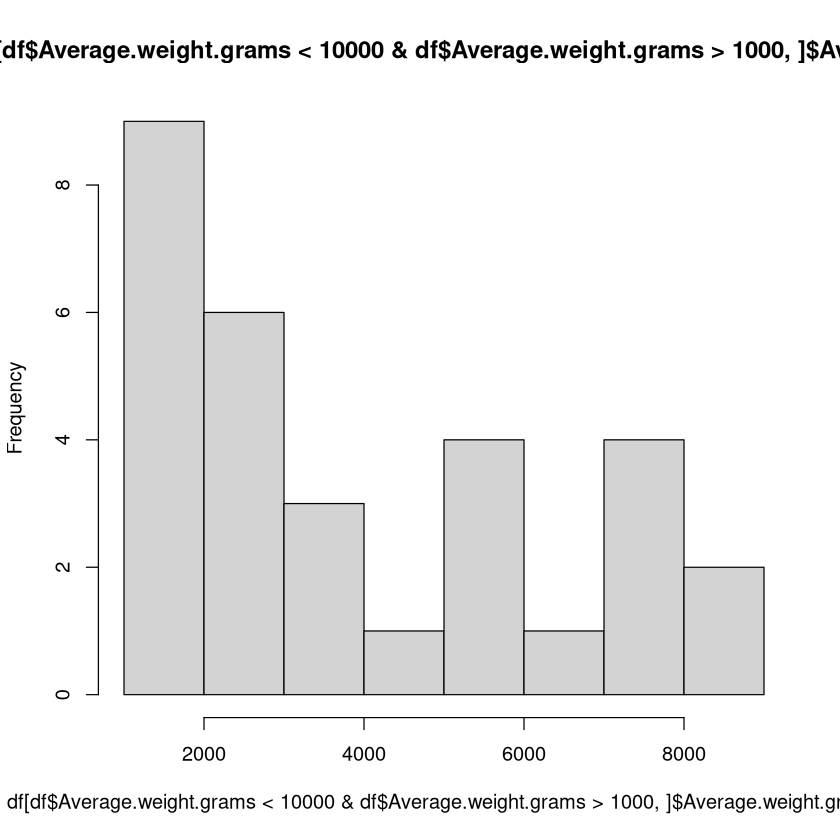

In [9]:
hist(df[df$Average.weight.grams < 10000 & df$Average.weight.grams > 1000, ]$Average.weight.grams)

- ```median(arg)``` - возвращает медиану диапазона

In [10]:
cat("Медианное значение веса рыб", median(df$Average.weight.grams), sep=" = ")

Медианное значение веса рыб = 1650

## Save the data sets

In [11]:
write.csv(df, file = "resources/processed-1.csv", row.names = FALSE)

## Exit R

```q()``` - to exit R

# LABORATORY

## Prepare working environment for the Lab and load data files

In [12]:
rm(list = ls()) # Удаляем объекты, аллоцированные в 2.1 части
Income <- read.table("resources/1-lab/zipIncome.txt", header = TRUE, sep = "|", fill = TRUE)

### Замечено, что на 32039 строке ошибка парсинга: столбцов меньше чем в предыдущих. "Починим" это параметром fill=TRUE - это заполнит пустую строку

In [13]:
Income[32037:32040, ]

,zip_prefixes,meanhouseholdincome
,<chr>,<dbl>
32037,9,168164.3
32038,9,180292.5
32039,(32038 rows),NA
NA,NA,NA


### Видно, что 32039 это последняя строка в файле, которая несет информацию о количестве строк в файле. Очистим наш датасет от мусора

In [14]:
Income <- Income[0:32038, ]

## Obtain summary statistics for Household Income and visualize data

- ```par()``` - настройка глобальных графических параметров вывода графиков
- ```mfrow``` - параметр ```par()```, который задает сетку размещения графиков

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
      0   37644   44163   48245   54373  250000 

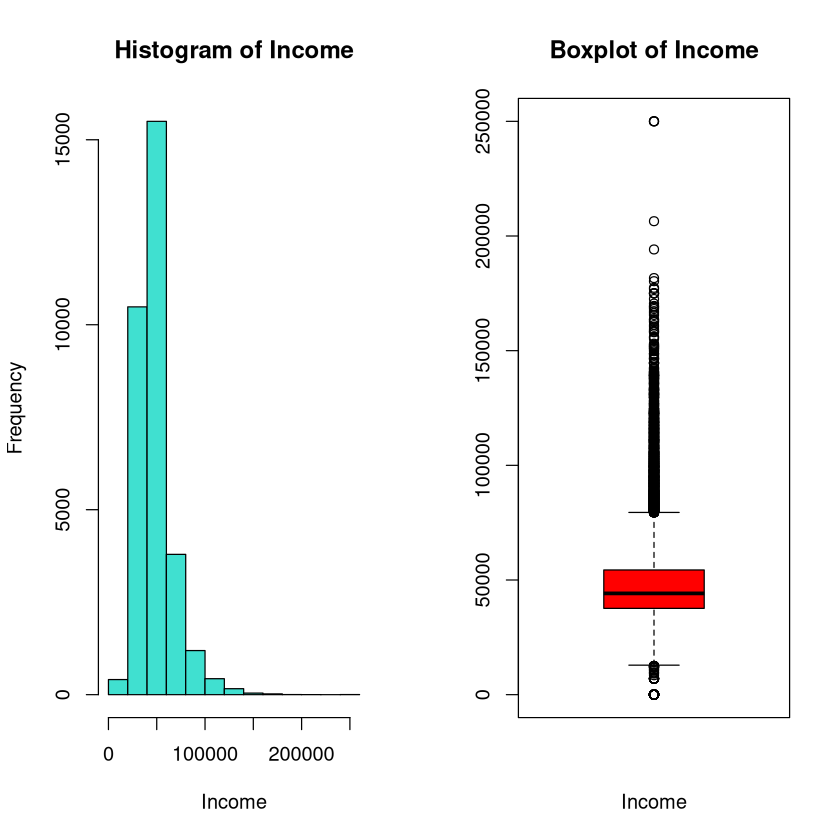

In [15]:
summary(Income$meanhouseholdincome)

par(mfrow = c(1,2)) # задаем сетку для графиков ( 1 строка, 2 столбца )
hist(Income$meanhouseholdincome, main = "Histogram of Income", xlab = "Income", col = "turquoise")
boxplot(Income$meanhouseholdincome, main = "Boxplot of Income", xlab = "Income", col = "red")

# Data Analysis in R

## Change the column names of your data frame so that zip_Prefix becomes zipCode and meanhouseholdincome becomes income.

- ```colnames(df)``` - возвращает поле, которое хранит имена колонок

In [16]:
colnames(Income) <- c("zipCode", "income")
head(Income)

,zipCode,income
,<chr>,<dbl>
1,0,0.00
2,0,0.00
3,0,0.00
4,0,0.00
5,0,0.00
6,0,12013.34


a. Analyze the summary of your data.  What are the mean and median average incomes?

In [17]:
summary(Income)
cat("Mean is ", mean(Income$income), "\nMedian is ", median(Income$income))

   zipCode              income      
 Length:32038       Min.   :     0  
 Class :character   1st Qu.: 37644  
 Mode  :character   Median : 44163  
                    Mean   : 48245  
                    3rd Qu.: 54373  
                    Max.   :250000  

Mean is  48245.24 
Median is  44163.48

b. Plot a scatter plot of the data.  Although this graph is not too informative, do you see any outlier values?  If so, what are they?

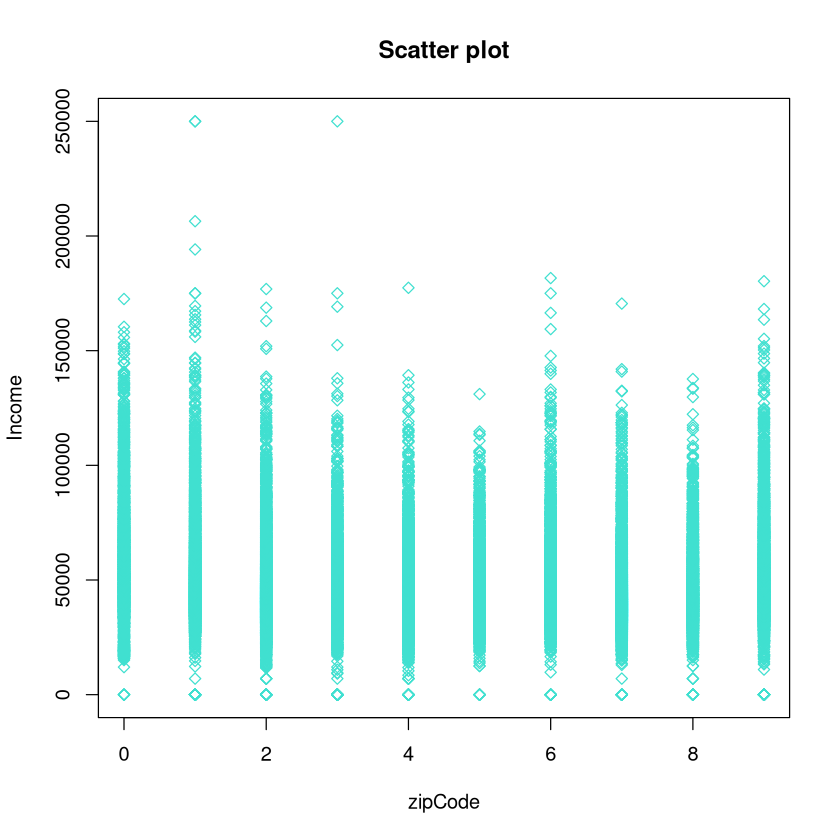

In [18]:
plot(Income$zipCode, Income$income,
     main = "Scatter plot",
     xlab = "zipCode",
     ylab = "Income",
     pch = 23, # plot character
     col = "turquoise"
)

Outliers:

In [19]:
print(Income[(Income$income > 200000 | Income$income == 0), ])

      zipCode   income
1           0      0.0
2           0      0.0
3           0      0.0
4           0      0.0
5           0      0.0
2425        1      0.0
2426        1      0.0
2427        1      0.0
2428        1      0.0
2429        1      0.0
2430        1      0.0
2431        1      0.0
2432        1      0.0
2433        1      0.0
2434        1      0.0
2435        1      0.0
2436        1      0.0
2437        1      0.0
2438        1      0.0
2439        1      0.0
2440        1      0.0
2441        1      0.0
2442        1      0.0
2443        1      0.0
2444        1      0.0
2445        1      0.0
2446        1      0.0
2447        1      0.0
2448        1      0.0
2449        1      0.0
2450        1      0.0
2451        1      0.0
2452        1      0.0
2453        1      0.0
2454        1      0.0
2455        1      0.0
5827        1 206451.6
5828        1 250000.0
5829        1 250000.0
5830        2      0.0
5831        2      0.0
5832        2      0.0
5833       

## In order to omit outliers, create a subset of the data so that:
$7,000 < income < $200,000

In [20]:
IncomeSubset <- Income[Income$income > 7000 & Income$income < 200000, ]

c.        What’s your new mean?

In [21]:
cat("New mean is", mean(IncomeSubset$income))

New mean is 48464.95

d.       Create a simple box plot of your data.  Be sure to add a title and label the axes.
- ```~``` - слева числовая переменная, справа категориальная переменная

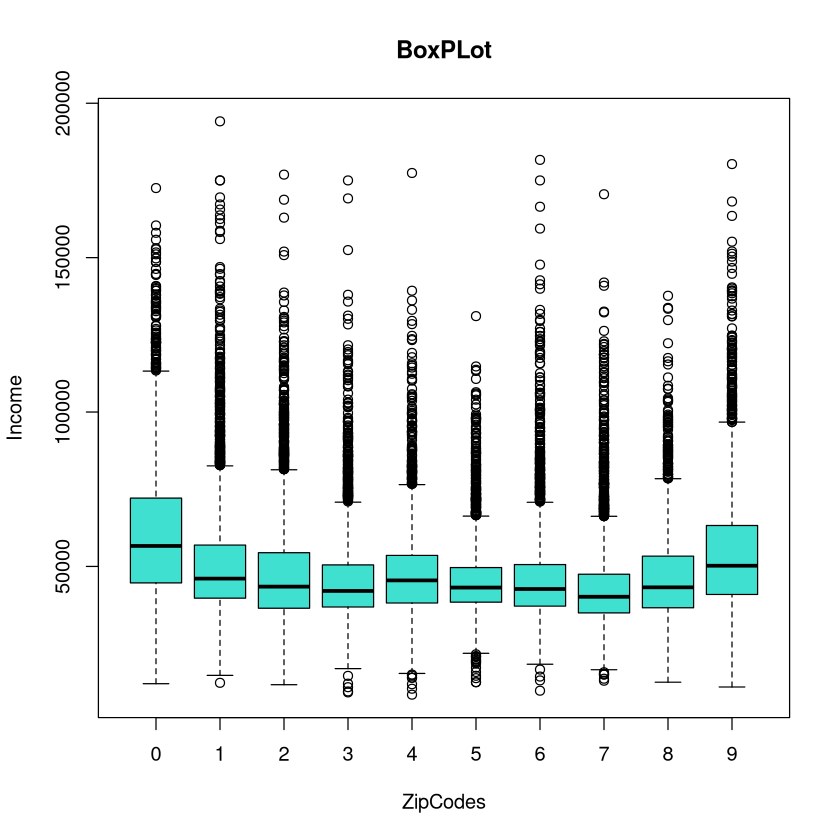

In [30]:
boxplot(income ~ zipCode, 
        data = IncomeSubset, 
        main = "BoxPLot", 
        xlab = "ZipCodes", 
        ylab = "Income",
        col = "turquoise"
       )

e.      In the box plot you created, notice that all of the income data is pushed towards the bottom of the graph because most average incomes tend to be low.  Create a new box plot where the y-axis uses a log scale.  Be sure to add a title and label the axes.

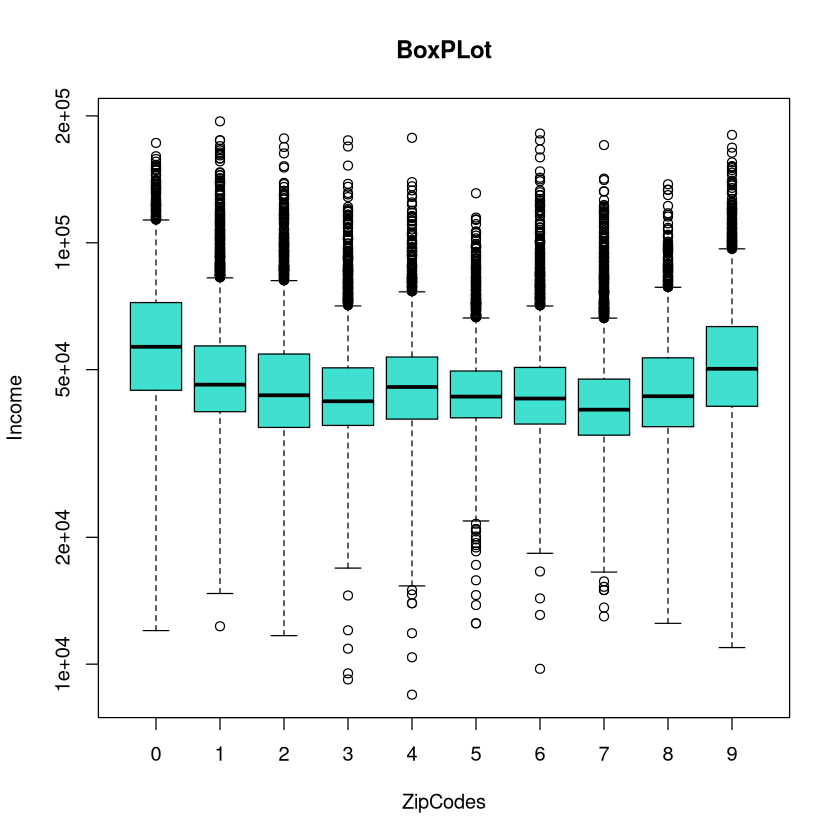

In [33]:
boxplot(income ~ zipCode, 
        data = IncomeSubset, 
        main = "BoxPLot", 
        log = "y",
        xlab = "ZipCodes", 
        ylab = "Income",
        col = "turquoise"
       )

## Use the ggplot library in R, which enables you to create graphs with several different types of plots layered over each other.  Be sure to read the documentation for ggplot and load the library ggplot2 (you may have to install this package into R). 

In [24]:
# install.packages("ggplot2", repos = "https://cran.rstudio.com/")
# Команда свыше скачивает библиотеку ggplot2

In [25]:
library(ggplot2) # подключаем библиотеку

Make a ggplot that consists of just a scatter plot using the function geom_point() with position = “jitter”  so that the data points are grouped by zip code.  Be sure to use ggplot’s function for taking the log10 of the y-axis data.  (Hint: for geom_point, have alpha=0.2).
- ```factor()``` - переводит в категории (Как при one-hot кодировании)

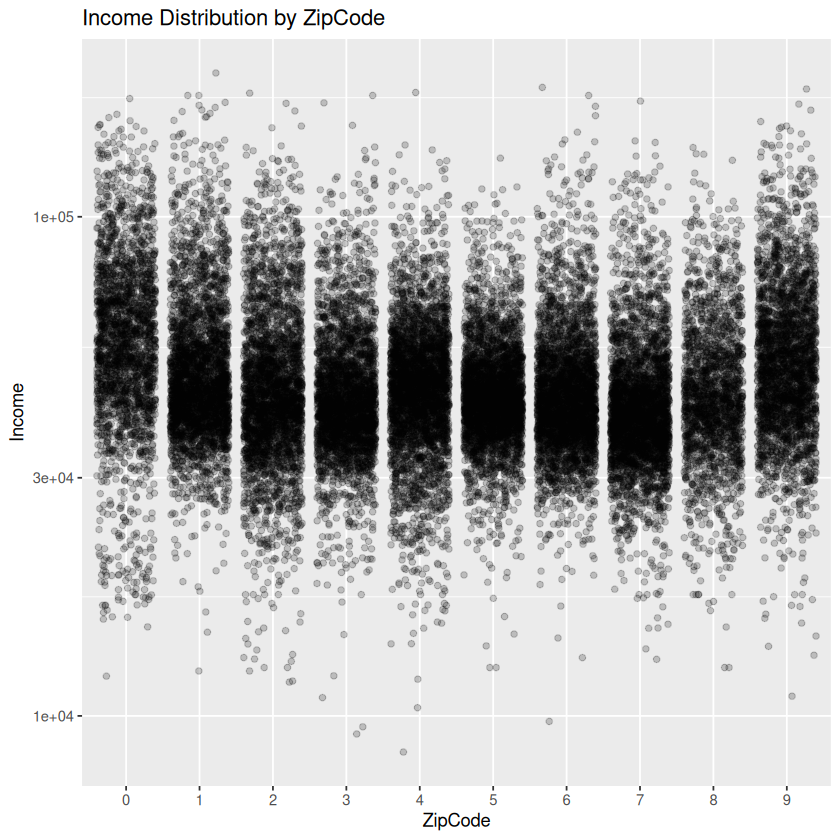

In [26]:
ggplot(IncomeSubset, aes(x = factor(zipCode), y = income)) +
    geom_point(position = "jitter", alpha = 0.2) +
    scale_y_log10() + # Делаем по игреку логарифмическую шкалу
    labs(
        title = "Income Distribution by ZipCode",
        x = "ZipCode",
        y = "Income"
    )
invisible(theme_minimal())

g.        Create a new ggplot by adding a box plot layer to your previous graph.  To do this, add the ggplot function geom_boxplot().  Also, add color to the scatter plot so that data points between different zip codes are different colors.  Be sure to label the axes and add a title to the graph.

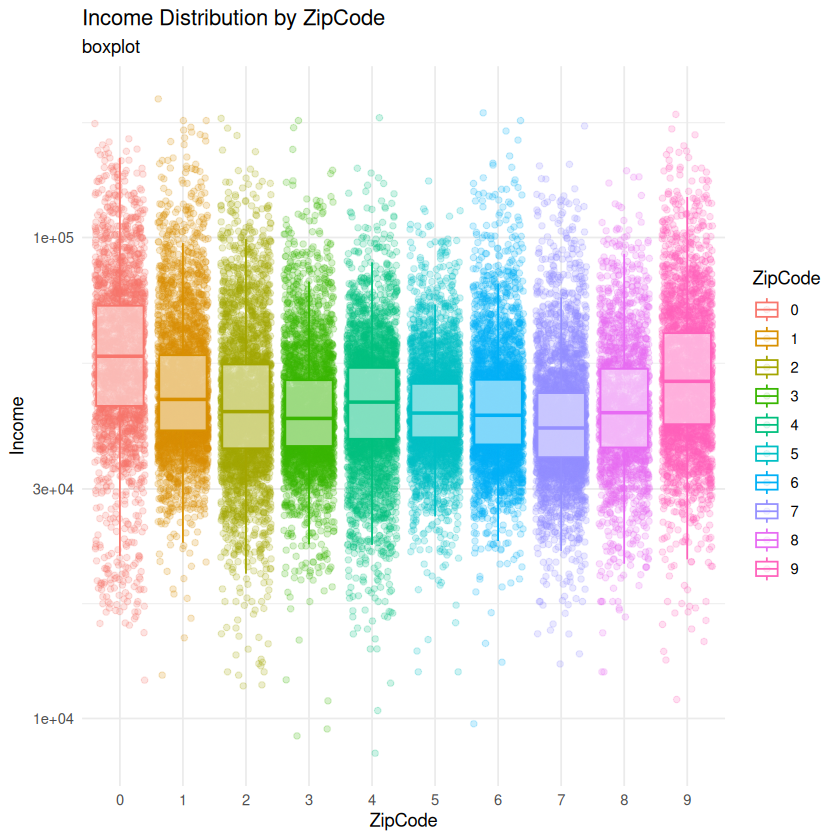

In [27]:
ggplot(IncomeSubset, aes(x = factor(zipCode), y = income, color = factor(zipCode))) +
    geom_point(position = "jitter", alpha = 0.2) +
    geom_boxplot(alpha = 0.5, outlier.shape = NA) +
    scale_y_log10() +
    labs(
        title = "Income Distribution by ZipCode",
        subtitle = "boxplot",
        x = "ZipCode",
        y = "Income",
        color = "ZipCode"
    ) +
    theme_minimal()

h.       What can you conclude from this data analysis/visualization?
- Средний доход у каждого ZipCode находится на относительно равном уровне, хотя 0 и 9 чуть выше в заработке, а 7 - напротив чуть ниже остальных в заработке
- Основываясь на коробочках, можно сказать, что медианнаый заработок выше всего у 0, а у 7 ниже всего